In [ ]:
# Cloud authentication.
from google.colab import auth
auth.authenticate_user()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import glob
import math
import datetime, os
plt.style.use("ggplot")
makeInstall = True

In [ ]:
# Necessary API's install to notebook VM.
if makeInstall:
    !pip install earthengine-api
    !pip install oauth2client
    !pip install google-api-python-client
    !pip install pygeoj
    makeInstall = False

import logging
import os
logging.getLogger('googleapicliet.discovery_cache').setLevel(logging.ERROR)

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# Tensorflow setup.
import os
# %tensorflow_version 2.x
import tensorflow as tf
print("We working with TF Version = ", tf.__version__)
# tf.enable_eager_execution()

We working with TF Version =  2.17.1


In [ ]:
try:
    resolver = tf.distribute.cluster_resolver.TPUClusterResolver()  # tpu='TPU v28'
    tf.config.experimental_connect_to_cluster(resolver)
    # This is the TPU initialization code that has to be at the beginning.
    tf.tpu.experimental.initialize_tpu_system(resolver)
    print("All devices: ", )
    for ntpu in tf.config.list_logical_devices('TPU'):
        print("      " ,ntpu)
except:
    device_name = tf.test.gpu_device_name()
    if device_name != '/device:GPU:0':
        raise SystemError('GPU device not found')
    else:
        print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


In [ ]:
# Folium setup.
# !pip install folium
import folium
print(folium.__version__)

# Define the URL format used for Earth Engine generated map tiles.
EE_TILES = 'https://earthengine.googleapis.com/map/{mapid}/{{z}}/{{x}}/{{y}}?token={token}'

0.18.0


In [ ]:
# General
GOAL_CLASS     = 'fotovoltaica'
VERSION        = '2';
GDRIVE         = 'unet-'+ GOAL_CLASS
FOLDER_TRAIN   = 'train_chips_fotoV2'
FOLDER_TEST    = 'test_chips_fotoV2'

#Local paths
BASE_PATH      = '/content/drive/MyDrive/'

# LOCAL_PATH     =  BASE_PATH  + '/unet-' + GOAL_CLASS
# MODEL_DIR      =  LOCAL_PATH + '/checkpoint/v' + VERSION
# OUTPUT_PATH    =  LOCAL_PATH + '/output/v' + VERSION
# biomes = ['CAATINGA','CERRADO','MATAATLANTICA']
# Exportation Configs
# BUCKET_patch   = BUCKET
FOLDER_patch   = 'allPatch'
# FOLDER_classification = 'mb7_'+ GOAL_CLASS + '_' + VERSION
# asset_SHPfoto = 'projects/mapbiomas-workspace/AMOSTRAS/col9/CAATINGA/Energias/shp_manual_fotovoltaicas_Br_2024'
# asset_SHPfoto = 'projects/mapbiomas-workspace/AMOSTRAS/col9/CAATINGA/Energias/polygons/polygons_base_paneis_fotovoltaicos_19_11'
# # asset_limitCaat = 'users/CartasSol/shapes/nCaatingaBff3500'
# asset_raster_biomas = 'projects/mapbiomas-workspace/AUXILIAR/biomas-raster-41'
# bandMosaic = ['B','G','R','N']
bandMos = ['B','G','R','N']
indexBands   = ['B','G','R','N','iia','evi','ri','gli','shape']
BANDS          = indexBands
RESPONSE       = 'supervised'
FEATURES       = BANDS + [RESPONSE]
# assetNICFI =  'projects/planet-nicfi/assets/basemaps/americas',
# Specify the size and shape of patches expected by the model.
KERNEL_SIZE  = 256
KERNEL_SHAPE = [KERNEL_SIZE, KERNEL_SIZE]
COLUMNS = [tf.io.FixedLenFeature(shape=KERNEL_SHAPE, dtype=tf.float32) for k in FEATURES]
FEATURES_DICT = dict(zip(FEATURES, COLUMNS))

# Sizes of the training and evaluation datasets.
TRAIN_SIZE = 0
EVAL_SIZE  = 0

# Specify model training parameters.
BATCH_SIZE  = 12
DROPOUT     = 0.3
EPOCHS      = 50
BUFFER_SIZE = 1000
LOSS        = 'BinaryCrossentropy'
METRICS     = ['RootMeanSquaredError','Hinge']

In [ ]:
# !ls /content/drive/MyDrive/train_chips_fotoV2

In [ ]:
FOLDER_TRAIN   = 'train_chips_fotoV3'
FOLDER_TEST    = 'eval_chips_fotoV3'
GDRIVE = '/content/drive/MyDrive/'
pathDrivetrain =  GDRIVE + FOLDER_TRAIN
pathDrivetest =  GDRIVE + FOLDER_TEST
print("folder do training ", pathDrivetrain)
print("folder do test ", pathDrivetest)

print("\n ----------- Lista de files TFRecords ----------------")
lstFiles = glob.glob(pathDrivetrain + '/*.gz')
print(f"Loading # {len(lstFiles)} files tfrecords ")
for cc, nameF in enumerate(lstFiles):
  if cc < 4:
    print("   ->   ", nameF)
print("-------" * 13 )

folder do training  /content/drive/MyDrive/train_chips_fotoV3
folder do test  /content/drive/MyDrive/eval_chips_fotoV3

 ----------- Lista de files TFRecords ----------------
Loading # 427 files tfrecords 
   ->    /content/drive/MyDrive/train_chips_fotoV3/train_fotoV_YY_2024_10_g0_10.tfrecord.gz
   ->    /content/drive/MyDrive/train_chips_fotoV3/train_fotoV_YY_2024_10_g1_10.tfrecord.gz
   ->    /content/drive/MyDrive/train_chips_fotoV3/train_fotoV_YY_2024_10_g2_10.tfrecord.gz
   ->    /content/drive/MyDrive/train_chips_fotoV3/train_fotoV_YY_2024_10_g3_10.tfrecord.gz
-------------------------------------------------------------------------------------------


In [ ]:
def parse_tfrecord(example_proto):
    """The parsing function.
    Read a serialized example into the structure defined by FEATURES_DICT.
    Args:
        example_proto: a serialized Example.
    Returns:
        A dictionary of tensors, keyed by feature name.
    """
    print("  KNOW TH FEATURES ")
    for kk, vv in FEATURES_DICT.items():
        print(kk, " ", vv)
    print(" ")
    return tf.io.parse_single_example(example_proto, FEATURES_DICT)


def to_tuple(inputs):
    """Function to convert a dictionary of tensors to a tuple of (inputs, outputs).
    Turn the tensors returned by parse_tfrecord into a stack in HWC shape.
    Args:
        inputs: A dictionary of tensors, keyed by feature name.
    Returns:
        A dtuple of (inputs, outputs).
    """
    # my_label = 1
    inputsList = []
    tmp = None
    for cc, kkey in enumerate(FEATURES):

        if cc < len(BANDS):
            # tmp = (inputs.get(key) - val_mean[cc]) / val_stdDev[cc]
            tmp = inputs.get(kkey)
            #   tmp = tmp.astype(np.float32)
            tmp = tmp / 10000
        else:
            tmp = inputs.get(kkey)
            #   tmp = tmp.astype(np.float32)
            # val_m = np.max(tmp)
            # if val_m == 0:
            #      my_label = 0
        # print("loadin kkey ", kkey, " with ", tmp.shape)
        inputsList.append(tmp)
    stacked = tf.stack(inputsList, axis=0)
    # Convert from CHW to HWC
    stacked = tf.transpose(stacked, [1, 2, 0])
    print("---- SIZE OF MATRIZ ENDED ------ ", stacked.shape)

    return stacked[:,:,:len(BANDS)], stacked[:,:,len(BANDS):]

def get_dataset(pathfile_train):
    """Function to read, parse and format to tuple a set of input tfrecord files.
    Get all the files matching the pattern, parse and convert to tuple.
    Args:
      pattern: A file pattern to match in a Cloud Storage bucket.
    Returns:
      A tf.data.Dataset
    """
    lst_filespath = tf.io.gfile.glob(pathfile_train)
    dataset = tf.data.TFRecordDataset(lst_filespath, compression_type='GZIP')
    dataset = dataset.map(parse_tfrecord, num_parallel_calls=5)
    dataset = dataset.map(to_tuple, num_parallel_calls=5)
    return dataset

In [ ]:
def get_training_dataset():
	"""Get the preprocessed training dataset
  Returns:
    A tf.data.Dataset of training data.
  """
	pathtrain = pathDrivetrain + '/train_fotoV_YY_*'
	print(f" --- {pathtrain} -------")
	dataset = get_dataset(pathtrain)
	dataset = dataset.shuffle(int(BUFFER_SIZE /2)).batch(BATCH_SIZE).repeat()
	return dataset

training = get_training_dataset()
# print(iter(training.take(1)).next())

 --- /content/drive/MyDrive/train_chips_fotoV3/train_fotoV_YY_* -------
  KNOW TH FEATURES 
B   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
G   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
R   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
N   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
iia   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
evi   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
ri   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
gli   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
shape   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
supervised   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
 
---- SIZE OF MATRIZ ENDED ------  (256, 256, 10)


In [ ]:
training.take(1)

<_TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 9), dtype=tf.float32, name=None), TensorSpec(shape=(None, 256, 256, 1), dtype=tf.float32, name=None))>

In [ ]:
tf_record_train = iter(training.take(1)).next()
img_train_lst = tf_record_train[0]
label_train_lst = tf_record_train[1]
print("Size of matriz Imagens dimensions ", img_train_lst.shape)
print("Size of matriz Labels dimensions ", label_train_lst.shape)

Size of matriz Imagens dimensions  (12, 256, 256, 9)
Size of matriz Labels dimensions  (12, 256, 256, 1)


In [ ]:
def get_eval_dataset():
    # Novas amostras na eval_2
	# glob = '/gdrive/MyDrive/' + FOLDER + '/' + EVAL_BASE + '*'
	glob = pathDrivetest + '/test_fotoV_YY_*'
	dataset = get_dataset(glob)
	dataset = dataset.shuffle(int(BUFFER_SIZE/2)).batch(BATCH_SIZE).repeat()
	return dataset

evaluation = get_eval_dataset()
#print(iter(evaluation.take(1)).next())

  KNOW TH FEATURES 
B   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
G   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
R   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
N   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
iia   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
evi   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
ri   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
gli   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
shape   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
supervised   FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)
 
---- SIZE OF MATRIZ ENDED ------  (256, 256, 10)


In [ ]:
tf_record_test = iter(evaluation.take(1)).next()
img_label_lst = tf_record_test[0]
label_label_lst = tf_record_test[1]
print("Size of matriz Imagens dimensions ", img_label_lst.shape)
print("Size of matriz Labels dimensions ", label_label_lst.shape)

Size of matriz Imagens dimensions  (12, 256, 256, 9)
Size of matriz Labels dimensions  (12, 256, 256, 1)


# Visualizar dataset of Patchs


In [ ]:
def hex_to_rgb(hex):
    return tuple(int(hex[i:i+2], 16) for i in (0, 2, 4))

def rgb_to_hex(r, g, b):
    return ('{:02X}' * 3).format(r, g, b)

def frame_image(img, frame_width):
    b = frame_width # border size in pixel
    ny, nx = img.shape[0], img.shape[1] # resolution / number of pixels in x and y
    if img.ndim == 3: # rgb or rgba array
        framed_img = np.zeros((b+ny+b, b+nx+b, img.shape[2]))
    elif img.ndim == 2: # grayscale image
        framed_img = np.zeros((b+ny+b, b+nx+b))
    framed_img[b:-b, b:-b] = img
    return framed_img

def convertInt16_to_Int8(myArray):
    nmin = np.min(myArray)
    nmax = np.max(myArray)
    # print("extreme before >> minimo ", nmin, "  |  maximo ", nmax)
    newArray = ((myArray - nmin) / (nmax - nmin)) * 255

    return newArray.astype(np.uint8)

In [ ]:
def drawContour(segm, hexcolor):

     # Fill contour "c" with white, make all else black  #fc8d59 (251,141,89)
    colorRGB =  hex_to_rgb(hexcolor[1:])
    segm = np.array(segm)                                             #(rgb(22,33,43))
    ContourR = np.where(segm == 0, colorRGB[0], segm)
    ContourG = np.where(segm == 0, colorRGB[1], segm)
    ContourB = np.where(segm == 0, colorRGB[2], segm)

    imgSeg = np.stack([ContourR,ContourG,ContourB])
    # print(imgSeg.shape)
    imgSeg = np.transpose(imgSeg,[2, 1, 0])

    return imgSeg

loading the first batch 


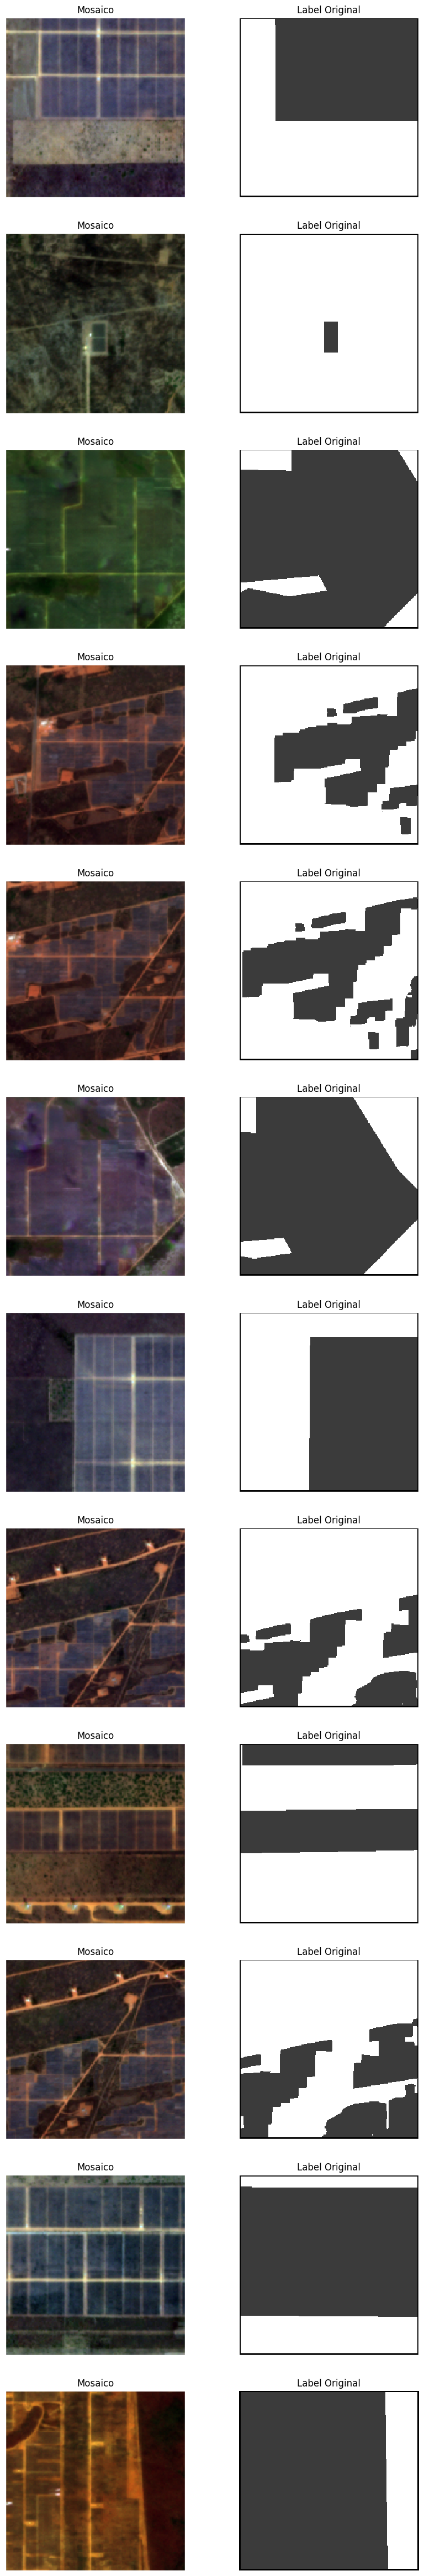

In [ ]:
print("loading the first batch ")
fig, ax = plt.subplots(figsize=[10,60], nrows=12, ncols=2)
for ii in range(12):
    bnd_blue = img_train_lst[ii, :, : , 0].numpy() * 10000
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = img_train_lst[ii, :, : , 1].numpy() * 1000
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = img_train_lst[ii, :, : , 2].numpy() * 10000
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))

    imgRGB = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(imgRGB,[2, 1, 0])
    # stackedS = np.transpose(stackedS)
    stackedS = label_train_lst[ii, :, :, 0].numpy()
    rgbLabelOri = np.array((1 - stackedS) * 255).astype(np.uint8)
    rgbLabelOri = drawContour(rgbLabelOri, '#3b3b3b')
    rgbLabelOri = frame_image(rgbLabelOri, 2)
    #tf.contrib.summary.image(str(epoch)+" ->Input/"+str(counter), stacked[0:3], step=0)

    # show original image
    ax[ii, 0].set_title('Mosaico', fontsize = 12)
    ax[ii, 0].imshow(imgRGB,interpolation='nearest',vmin=0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB
    # ax[ii, 0].imshow(cv2.cvtColor(imgRGB, cv2.COLOR_BGR2RGB), interpolation='none', vmin=24, vmax=250) # interpolation='nearest',
    ax[ii, 0].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 0].yaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 1].set_title('Label Original', fontsize = 12)
    ax[ii, 1].imshow(rgbLabelOri.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    ax[ii, 1].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 1].yaxis.set_major_locator(ticker.NullLocator())

plt.axis("off")
plt.show()

In [ ]:
len(indexBands)

9

In [ ]:
# Other UNET model

In [ ]:
# nomes e variaveis
data_saved = '13_12_2024'
metrica_proc = 'mean_io_u'  # 'val_accuracy' , 'mean_io_u', 'accuracy'
versionModel = 5
varMetrics = ['accuracy']
if metrica_proc == 'mean_io_u':
    varMetrics = [tf.keras.metrics.MeanIoU(num_classes= 1)]

print(f"metrica a utilizar name << {metrica_proc} >>  operador {varMetrics}")

metrica a utilizar name << mean_io_u >>  operador [<MeanIoU name=mean_io_u>]


In [ ]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda
from keras.optimizers import Adam
from keras.layers import Activation, MaxPool2D, Concatenate

def conv_block(input, num_filters):
    conv_output = Conv2D(num_filters, (3, 3), padding='same')(input)
    conv_output = BatchNormalization()(conv_output)
    conv_output = Activation('relu')(conv_output)

    conv_output = Conv2D(num_filters, (3, 3), padding='same')(conv_output)
    conv_output = BatchNormalization()(conv_output)
    conv_output = Activation('relu')(conv_output)

    return conv_output

def encoder_block(input, num_filters):
    conv_output = conv_block(input, num_filters)
    pooling_output = MaxPooling2D((2,2), strides=(2, 2))(conv_output)

    return conv_output, pooling_output

def decoder_block(input_tensor, skip_features, num_filters):
    transposed = Conv2DTranspose(num_filters, (2,2), strides=2, padding='same')(input_tensor)
    concat_result = Concatenate()([transposed, skip_features])
    conv_output = conv_block(concat_result, num_filters)
    return conv_output

def build_unet(input_shape, num_classes):
    inputs = Input(input_shape)

    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    b1 = conv_block(p4, 1024)

    d1 = decoder_block(b1, s4, 512)
    d2 = decoder_block(d1, s3, 256)
    d3 = decoder_block(d2, s2, 128)
    d4 = decoder_block(d3, s1, 64)

    final_layer = Conv2D(num_classes, 1, padding='same', activation='sigmoid')
    outputs = final_layer(d4)

    model = Model(inputs, outputs, name='U-Net')
    return model

# Função para calcular o Índice de Jaccard
def jaccard_index(y_true, y_pred):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return intersection / union


def get_model():
    numberBnd = len(indexBands)
    my_model = build_unet(input_shape=(256,256, numberBnd), num_classes=1)
    print(my_model.summary())
    my_model.compile(
        optimizer= Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics= varMetrics
    )
    return my_model


# Model Selection/load
#

In [ ]:
# !pip install pydot
# !pip install graphviz

In [ ]:

from tensorflow.keras.utils import model_to_dot
from tensorflow.keras.utils import plot_model
from IPython.display import Image
import pydot
import graphviz
modelUNet = get_model() # UNET
#m = FCN_DK3(2, 256, 256)# FCN-DK
# Image(model_to_dot(modelUNet, show_shapes=True, show_layer_names=True, rankdir='TB',expand_nested=False, dpi=60, subgraph=False).create(prog='dot',format='png'))
nEpoch = 150
EPOCH = 0
# 08-12-2024
CHECK_MODEL_DIR = f'/content/drive/MyDrive/checkpoint/fotov1/cpV{versionModel}-0.ckpt'
# CHECK_MODEL_DIR = MODEL_DIR+'/cp-0'+str(EPOCH)+'.ckpt'

#m.load_weights(CHECK_MODEL_DIR)
print(modelUNet.summary())
print("we save the weigths in >>> ", CHECK_MODEL_DIR)


Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1             │ (None, 256, 256, 9)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_19 (Conv2D)        │ (None, 256, 256, 64)   │          5,248 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_18    │ (None, 256, 256, 64)   │            256 │ conv2d_19[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_18             │ (None, 256, 256, 64)   │              0 │ batch_normalization_1… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_20 (Conv2D)        │ (None, 256, 256, 64)   │         36,928 │ activation_18[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_19    │ (None, 256, 256, 64)   │            256 │ conv2d_20[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_19             │ (None, 256, 256, 64)   │              0 │ batch_normalization_1… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_4           │ (None, 128, 128, 64)   │              0 │ activation_19[0][0]    │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_21 (Conv2D)        │ (None, 128, 128, 128)  │         73,856 │ max_pooling2d_4[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_20    │ (None, 128, 128, 128)  │            512 │ conv2d_21[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_20             │ (None, 128, 128, 128)  │              0 │ batch_normalization_2… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_22 (Conv2D)        │ (None, 128, 128, 128)  │        147,584 │ activation_20[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_21    │ (None, 128, 128, 128)  │            512 │ conv2d_22[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_21             │ (None, 128, 128, 128)  │              0 │ batch_normalization_2… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_5      

 Total params: 31,058,753 (118.48 MB)

 Trainable params: 31,046,977 (118.43 MB)

 Non-trainable params: 11,776 (46.00 KB)

None


... (2 outputs left out)

 Total params: 31,058,753 (118.48 MB)

 Trainable params: 31,046,977 (118.43 MB)

 Non-trainable params: 11,776 (46.00 KB)

None
we save the weigths in >>>  /content/drive/MyDrive/checkpoint/fotov1/cpV5-0.ckpt


In [ ]:
modelTreined = False
procTreinar = True
print("dir of check_point \n   =>", CHECK_MODEL_DIR)

dir of check_point 
   => /content/drive/MyDrive/checkpoint/fotov1/cpV5-0.ckpt


In [ ]:
epoch = 0
checkpoint_path = f"/content/drive/MyDrive/checkpoint/fotov1/cpV{versionModel}.weights.keras"
checkpoint_dir = os.path.dirname(checkpoint_path)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
# tf.logging.set_verbosity(tf.logging.ERROR)
# trainingPolysList
# evalPolysList
# numero_pol_train =  78
# numero_pol_test = 22
# n = 10 # Number of shards in each polygon.
# N = 120 # Total sample size in each polygon.
# TRAIN_SIZE = numero_pol_train * N
# EVAL_SIZE = numero_pol_test * N

# print("training size == ", TRAIN_SIZE)
# print("testing size == ", EVAL_SIZE)
# print(TRAIN_SIZE / BATCH_SIZE)

# tensorboard = tf.keras.callbacks.TensorBoard(log_dir='output/v'+VERSION+'/log_model',write_images=True)
# 'accuracy','binary_accuracy','RootMeanSquaredError','Hinge'
cp_callback = tf.keras.callbacks.ModelCheckpoint(
                                  filepath= checkpoint_path,
                                  monitor= 'val_mean_io_u',      #  'val_accuracy',val_mean_io_u, val_loss
                                  mode= 'min',
                                  verbose= 1,
                                  save_weights_only=False,
                                  save_best_only=True,
                                  save_freq=20
                                )
# img_callback = tf.keras.callbacks.LambdaCallback(on_epoch_end= previewClass)
# [cp_callback,tensorboard,img_callback]
# m.save_weights(checkpoint_path.format(epoch=0))
callbacksfun = [cp_callback]  # ,tensorboard
#gpu_options = tf.GPUOptions(allow_growth=False)
# session = tf.compat.v1.InteractiveSession()
# Save the weights using the `checkpoint_path` format
# modelUNet.save_weights(checkpoint_path.format(epoch=0))
# with tf.device('/device:GPU:0'):
if not modelTreined and procTreinar:
    resultado = modelUNet.fit(
            x= training,
            epochs= nEpoch,
            initial_epoch= 0,  # REMEBER TO CHANGE THIS INITIAL EPOCH PARAM, WHEN OTHER MODEL HAS BEEN LOADED
            steps_per_epoch= 200, #int(TRAIN_SIZE / BATCH_SIZE),
            verbose= 1,
            shuffle= True,
            validation_data= evaluation,
            validation_steps= 50,
            callbacks = callbacksfun
            )
    modelTreined = True


Epoch 1/150
 20/200 ━━━━━━━━━━━━━━━━━━━━ 2:03 683ms/step - loss: 0.4642 - mean_io_u: 1.0000

/usr/local/lib/python3.10/dist-packages/keras/src/callbacks/model_checkpoint.py:199: UserWarning: Can save best model only with val_mean_io_u available, skipping.
  self._save_model(epoch=self._current_epoch, batch=batch, logs=logs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 281s 994ms/step - loss: 0.2729 - mean_io_u: 1.0000 - val_loss: 5.0550 - val_mean_io_u: 1.0000
Epoch 2/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 190s 952ms/step - loss: 0.1687 - mean_io_u: 1.0000 - val_loss: 0.8181 - val_mean_io_u: 1.0000
Epoch 3/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 183s 915ms/step - loss: 0.1310 - mean_io_u: 1.0000 - val_loss: 2.1133 - val_mean_io_u: 1.0000
Epoch 4/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 182s 911ms/step - loss: 0.1586 - mean_io_u: 1.0000 - val_loss: 0.4471 - val_mean_io_u: 1.0000
Epoch 5/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 169s 845ms/step - loss: 0.1571 - mean_io_u: 1.0000 - val_loss: 2.8365 - val_mean_io_u: 1.0000
Epoch 6/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 151s 756ms/step - loss: 0.2206 - mean_io_u: 1.0000 - val_loss: 0.4925 - val_mean_io_u: 1.0000
Epoch 7/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 135s 678ms/step - loss: 0.1399 - mean_io_u: 1.0000 - val_loss: 0.5189 - val_mean_io_u: 1.0000
Epoch 8/150
200/200 ━━━━━━━━━━━━━━━━━━━━ 135s 676ms/step - loss: 0.

In [ ]:
resultado.history
data_saved = '13_12_2024'
# metrica_proc = 'accuracy'  # 'val_accuracy' , 'mean_io_u'

In [ ]:
# Save the entire model as a SavedModel.
# !mkdir -p saved_model
path_saveModel = f'/content/drive/MyDrive/energias/model/model_{metrica_proc}_{data_saved}.keras'
modelAccurOiu = False
if modelTreined:
    modelUNet.save(path_saveModel)

In [ ]:
path_base = '/content/drive/MyDrive/energias/model'
print("path base ", path_base)
name_csv_history = f'/valores_{metrica_proc}_histogram4L_{data_saved}.csv'
if modelTreined:
    dict_Val = {
        'loss': resultado.history['loss'],
        'val_loss': resultado.history['val_loss']
    }
    if metrica_proc == 'accuracy':
        dict_Val['accuracy'] = resultado.history[metrica_proc]
        dict_Val['val_accuracy'] = resultado.history[f'val_{metrica_proc}']
    elif metrica_proc == 'mean_io_u':
        dict_Val['mean_io_u'] = resultado.history[metrica_proc]
        dict_Val['val_mean_io_u'] = resultado.history[f'val_{metrica_proc}']

    dfVal = pd.DataFrame.from_dict(dict_Val);
    dfVal.to_csv(path_base + name_csv_history);

In [ ]:
csv_saved = True
try:
    print("número de rows and Cols saved ", dfVal.shape)
except:
    try:
        dfVal = pd.read_csv(path_base + name_csv_history)
        print("número de rows and Cols saved ", dfVal.shape)
    except:
        csv_saved= False

In [ ]:
if csv_saved:
    epochs_range = range(dfVal[metrica_proc].shape[0])
    plt.figure(figsize=(18,7))
    plt.subplot(1,2,1)
    plt.plot(epochs_range, dfVal[metrica_proc], label = f'Training {metrica_proc}')
    plt.plot(epochs_range, dfVal[f'val_{metrica_proc}'], label = f'Validation {metrica_proc}')
    plt.title(metrica_proc)

    plt.subplot(1,2,2)
    plt.plot(epochs_range, dfVal['loss'], label = 'Training Loss')
    plt.plot(epochs_range, dfVal['val_loss'], label = 'Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

In [ ]:
# if not modelUNet:
# we have to load by weigth
fileweigthpath =  f'/content/drive/MyDrive/checkpoint/fotov1/cpV{versionModel}-0.weights.keras'
modelUNet.load_weights(fileweigthpath)


/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 166 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
modelTreined = True
avaliar = False

In [ ]:
pathtoSaveModel = f'/content/drive/MyDrive/energias/model/model_{metrica_proc}_{data_saved}.keras'
if modelTreined:
    modelUNet.save(pathtoSaveModel)

else:
    modelUNet = tf.keras.models.load_model(pathtoSaveModel)
    modelUNet.summary()

In [ ]:
if avaliar:
    resultado = modelUNet.evaluate(evaluation)
    print("Restored model, accuracy: {:5.2f}%".format(resultado))

  78036/Unknown 17854s 228ms/step - accuracy: 0.9623 - loss: 0.2452